# 窗口 RANSAC 抛物线轨迹清洗

**思路**：滑动窗口 × RANSAC 抛物线拟合 → 每帧独立判断，不依赖 bounce 分段

```
对每一帧 i:
  取窗口 [i-half, i+half] 内的所有有效点
    │
    ▼
  RANSAC 拟合抛物线 (随机抽 4 点 × 50~100 次)
  模型: x(t)=ax·t + bx,  y(t)=ay·t² + by·t + cy
  每个点的 inlier 判定用自适应阈值 (透视缩放 + 置信度缩放)
    │
    ▼
  用 best 抛物线算当前帧 i 的预测位置
    │
    ├── raw 点离预测 < 自适应阈值 → inlier: 用抛物线平滑值
    ├── raw 点离预测 > 自适应阈值 → outlier: 用抛物线值外推替换
    └── raw 点不存在              → 空缺: 用抛物线值填补
```

**自适应阈值**：`threshold = base_thresh × 透视缩放 × 置信度缩放`
- 近端（y 大）→ 阈值大（同样位移像素多），远端（y 小）→ 阈值小
- 高置信度 → 阈值放宽，低置信度 → 阈值收紧

**可视化**：视频上画紫色拟合曲线 + 绿色上下文点，类似 testtraj 的 SHOW_PRED_CURVE

In [ ]:
import json
import os
import sys
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name in {"scripts", "experiments"} and PROJECT_ROOT.parent.name == "cv":
    PROJECT_ROOT = PROJECT_ROOT.parents[1]
elif PROJECT_ROOT.name == "cv":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from cv.tracking.trajectory import split_track_improved, interpolation

# ===== 配置 =====
BALL_JSON_PATH = PROJECT_ROOT / "cv/data/output/ball_coords_raw.json"
FALLBACK_INPUT_VIDEO = PROJECT_ROOT / "cv/data/input/finaltest2.mp4"
INPUT_VIDEO = str(FALLBACK_INPUT_VIDEO)

# ---------- 窗口 RANSAC 参数 ----------
WINDOW_HALF   = 10       # 单侧窗口半径
RANSAC_ITERS  = 80       # RANSAC 迭代次数
BASE_INLIER_THRESH = 16  # 基础 inlier 阈值 (px)
MIN_POINTS    = 4        # 窗口内最少有效点数
FIT_DEGREE_X  = 1        # x(t) 拟合阶数
FIT_DEGREE_Y  = 2        # y(t) 拟合阶数
T_NORMALIZE   = True     # t 用相对帧号

# ---------- 透视缩放 ----------
FAR_THRESH_SCALE  = 0.65
NEAR_THRESH_SCALE = 2.3

# ---------- 置信度缩放 ----------
CONF_LOW  = 0.50
CONF_HIGH = 1.00
CONF_THRESH_SCALE_LOW  = 0.75
CONF_THRESH_SCALE_HIGH = 1.60

# ---------- 可视化 ----------
INITIAL_RANSAC_CSV_PATH = PROJECT_ROOT / "cv/data/output/winransac_initial_trajectory_candidate.csv"
OUTPUT_VIDEO = str(PROJECT_ROOT / "cv/data/output/winransac_preview.mp4")
SHOW_PRED_CURVE = True   # 视频中画拟合曲线
CURVE_TINT = 1           # 曲线采样间隔 (帧)
INTERP_MAX_JUMP_PX_PER_FRAME = 100  # 缺失帧插值的基准连续性保护阈值
INTERP_FAR_SCALE = 0.65
INTERP_NEAR_SCALE = 2.30

In [39]:
# ===== 从 ball_coords_raw.json 读取 Viterbi-lite 主球轨迹 =====

def _as_float_pair(pixel):
    if pixel is None or len(pixel) < 2:
        return None
    x, y = pixel[0], pixel[1]
    if x is None or y is None:
        return None
    return (float(x), float(y))


def _finite_float(value, default=np.nan):
    if value is None:
        return default
    try:
        value = float(value)
    except (TypeError, ValueError):
        return default
    return value if np.isfinite(value) else default


def _resolve_source_video(metadata):
    candidates = []
    source_video_path = metadata.get("source_video_path")
    if source_video_path:
        candidates.append(Path(source_video_path))
    source_video = metadata.get("source_video")
    if source_video:
        candidates.extend([
            PROJECT_ROOT / "cv/data/input" / source_video,
            PROJECT_ROOT / "cv/data/output" / source_video,
            BALL_JSON_PATH.parent / source_video,
        ])
    candidates.append(FALLBACK_INPUT_VIDEO)
    for path in candidates:
        if path and path.exists():
            return path
    return FALLBACK_INPUT_VIDEO


def load_ball_coords_json(path):
    with path.open("r", encoding="utf-8") as handle:
        payload = json.load(handle)
    metadata = payload.get("metadata", {})

    if "ball_coords" in payload:
        rows = payload["ball_coords"]
    elif "frames" in payload:
        rows = []
        for index, frame in enumerate(payload["frames"]):
            ball = frame.get("ball") or {}
            rows.append({
                "frame_index": frame.get("frame_index", index),
                "pixel": ball.get("pixel") if isinstance(ball, dict) else None,
                "confidence": ball.get("confidence", ball.get("heat_conf")) if isinstance(ball, dict) else None,
            })
    else:
        raise ValueError("Unsupported JSON format: expected 'ball_coords' or 'frames'.")

    max_frame_index = max((int(row.get("frame_index", i)) for i, row in enumerate(rows)), default=-1)
    total_frames = int(metadata.get("total_frames") or max(max_frame_index + 1, len(rows)))
    total_frames = max(total_frames, max_frame_index + 1, len(rows))

    coords = [None] * total_frames
    confidences = [np.nan] * total_frames
    statuses = [None] * total_frames
    for default_index, row in enumerate(rows):
        frame_index = int(row.get("frame_index", default_index))
        if frame_index < 0 or frame_index >= total_frames:
            continue
        coords[frame_index] = _as_float_pair(row.get("pixel"))
        conf = row.get("confidence")
        if conf is None:
            conf = row.get("heat_conf")
        confidences[frame_index] = _finite_float(conf)
        statuses[frame_index] = row.get("tracking_status")

    return payload, metadata, coords, confidences, statuses


payload, ball_metadata, raw_coords, raw_heat_conf, raw_tracking_status = load_ball_coords_json(BALL_JSON_PATH)
INPUT_VIDEO = str(_resolve_source_video(ball_metadata))

cap = cv2.VideoCapture(INPUT_VIDEO)
video_fps = cap.get(cv2.CAP_PROP_FPS) if cap.isOpened() else 0
video_fw = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) if cap.isOpened() else 0
video_fh = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)) if cap.isOpened() else 0
video_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) if cap.isOpened() else 0
cap.release()

fps = _finite_float(ball_metadata.get("fps"), video_fps if video_fps else 30.0)
fw = int(ball_metadata.get("video_width") or video_fw or 1920)
fh = int(ball_metadata.get("video_height") or video_fh or 1080)
ntotal = len(raw_coords)

n_det = sum(1 for point in raw_coords if point is not None)
vc = [conf for conf in raw_heat_conf if not np.isnan(conf)]
print(f'JSON: {BALL_JSON_PATH}')
print(f'video: {INPUT_VIDEO}')
print(f'读取完成: {len(raw_coords)} 帧, 主球检测率 {n_det/max(len(raw_coords),1)*100:.1f}%')
if video_total and video_total != ntotal:
    print(f'注意: JSON 帧数 {ntotal} 与视频帧数 {video_total} 不一致，RANSAC 按 JSON 帧数运行。')
if vc:
    print(f'confidence: mean={np.mean(vc):.3f}  min={np.min(vc):.3f}  max={np.max(vc):.3f}')

JSON: /Users/mac/PycharmProjects/tennis_data_master/cv/data/output/ball_coords_raw.json
video: /Users/mac/PycharmProjects/tennis_data_master/cv/data/input/real60.mp4
读取完成: 866 帧, 主球检测率 73.4%
confidence: mean=0.972  min=0.228  max=1.000


In [40]:
# ===== 工具函数 =====

def is_valid(p):
    if p is None: return False
    try: return not (np.isnan(p[0]) or np.isnan(p[1]))
    except (TypeError, IndexError): return False

def last_valid_coord_before(coords, index):
    for prev_index in range(index - 1, -1, -1):
        if is_valid(coords[prev_index]):
            return prev_index, coords[prev_index]
    return None, None

# ------ 自适应阈值 ------

def perspective_threshold_scale(point_y, frame_h, far_scale=FAR_THRESH_SCALE, near_scale=NEAR_THRESH_SCALE):
    if frame_h <= 0 or point_y is None or np.isnan(point_y): return 1.0
    y_ratio = float(np.clip(point_y / frame_h, 0.0, 1.0))
    return far_scale + y_ratio * (near_scale - far_scale)

def confidence_threshold_scale(conf, conf_low=CONF_LOW, conf_high=CONF_HIGH,
                                scale_low=CONF_THRESH_SCALE_LOW, scale_high=CONF_THRESH_SCALE_HIGH):
    if conf is None or np.isnan(conf): return 1.0
    ratio = (float(conf) - conf_low) / max(conf_high - conf_low, 1e-6)
    ratio = float(np.clip(ratio, 0.0, 1.0))
    return scale_low + ratio * (scale_high - scale_low)

def adaptive_threshold(base_thresh, point_y, conf, frame_h):
    return base_thresh * perspective_threshold_scale(point_y, frame_h) * confidence_threshold_scale(conf)


def interp_jump_threshold(point_y, frame_h):
    return INTERP_MAX_JUMP_PX_PER_FRAME * perspective_threshold_scale(
        point_y,
        frame_h,
        far_scale=INTERP_FAR_SCALE,
        near_scale=INTERP_NEAR_SCALE,
    )

# ------ 窗口 RANSAC ------

def _collect_window(raw_coords, heat_confs, i, half, n, frame_h):
    w_start, w_end = max(0, i - half), min(n - 1, i + half)
    frames, xs, ys, threshs, abs_frames = [], [], [], [], []
    for j in range(w_start, w_end + 1):
        if j == i: continue
        if is_valid(raw_coords[j]):
            t = j - i if T_NORMALIZE else j
            py = raw_coords[j][1]
            cf = heat_confs[j] if j < len(heat_confs) else np.nan
            frames.append(t)
            abs_frames.append(j)
            xs.append(raw_coords[j][0])
            ys.append(py)
            threshs.append(adaptive_threshold(BASE_INLIER_THRESH, py, cf, frame_h))
    return frames, xs, ys, threshs, abs_frames

def ransac_parabola(frames, xs, ys, threshs, n_iters, deg_x, deg_y):
    n_pts = len(frames)
    if n_pts < MIN_POINTS: return None, 0, None
    t = np.array(frames, dtype=np.float64)
    x_arr, y_arr = np.array(xs, dtype=np.float64), np.array(ys, dtype=np.float64)
    th_arr = np.array(threshs, dtype=np.float64)
    sample_size = min(n_pts, max(deg_x + 1, deg_y + 1) + 1)
    best_inliers, best_cx, best_cy, best_mask = 0, None, None, None
    rng = np.random.RandomState(42)
    for _ in range(n_iters):
        idx = rng.choice(n_pts, sample_size, replace=False)
        try:
            cx = np.polyfit(t[idx], x_arr[idx], deg_x)
            cy = np.polyfit(t[idx], y_arr[idx], deg_y)
        except (np.linalg.LinAlgError, ValueError): continue
        residuals = np.sqrt((x_arr - np.polyval(cx, t))**2 + (y_arr - np.polyval(cy, t))**2)
        mask = residuals < th_arr
        n_in = mask.sum()
        if n_in > best_inliers:
            best_inliers, best_cx, best_cy, best_mask = n_in, cx, cy, mask
    if best_inliers >= max(deg_x + 1, deg_y + 1) and best_mask is not None and best_mask.sum() >= 3:
        try:
            best_cx = np.polyfit(t[best_mask], x_arr[best_mask], deg_x)
            best_cy = np.polyfit(t[best_mask], y_arr[best_mask], deg_y)
        except (np.linalg.LinAlgError, ValueError): pass
    return (best_cx, best_cy), best_inliers, best_mask

def predict_parabola(params, t_rel):
    if params is None: return (np.nan, np.nan)
    cx, cy = params
    if cx is None or cy is None: return (np.nan, np.nan)
    return (float(np.polyval(cx, t_rel)), float(np.polyval(cy, t_rel)))

def sample_parabola_curve(params, i, half, n, tint=1):
    """
    用拟合参数采样窗口范围内的抛物线曲线，用于可视化。
    返回 curve_pts: [(x,y), ...]  从窗口左端到右端每隔 tint 帧采样
    """
    if params is None: return []
    cx, cy = params
    if cx is None or cy is None: return []
    w_start, w_end = max(0, i - half), min(n - 1, i + half)
    pts = []
    for t_abs in range(w_start, w_end + 1, tint):
        t_rel = t_abs - i if T_NORMALIZE else t_abs
        px = float(np.polyval(cx, t_rel))
        py = float(np.polyval(cy, t_rel))
        if np.isfinite(px) and np.isfinite(py):
            pts.append((int(round(px)), int(round(py))))
    return pts

print('工具函数已加载')

工具函数已加载


In [41]:
# ===== 窗口 RANSAC 清洗整条轨迹 =====

n = len(raw_coords)
cleaned_coords = [(np.nan, np.nan)] * n
point_status    = ['gap'] * n
fit_info        = [None] * n
adaptive_thresh_per_frame = [BASE_INLIER_THRESH] * n

pbar = tqdm(total=n, desc='窗口 RANSAC')
for i in range(n):
    # 1. 收集窗口点
    frames, xs, ys, threshs, abs_frames = _collect_window(raw_coords, raw_heat_conf, i, WINDOW_HALF, n, fh)

    if len(frames) < MIN_POINTS:
        if is_valid(raw_coords[i]):
            cleaned_coords[i] = (float(raw_coords[i][0]), float(raw_coords[i][1]))
            point_status[i] = 'raw_kept'
        pbar.update(1)
        continue

    # 2. RANSAC 拟合
    params, n_inliers, _ = ransac_parabola(
        frames, xs, ys, threshs, n_iters=RANSAC_ITERS, deg_x=FIT_DEGREE_X, deg_y=FIT_DEGREE_Y)

    if params is None:
        if is_valid(raw_coords[i]):
            cleaned_coords[i] = (float(raw_coords[i][0]), float(raw_coords[i][1]))
            point_status[i] = 'raw_kept'
        pbar.update(1)
        continue

    # 3. 预测 + 判定
    t_self = 0.0 if T_NORMALIZE else float(i)
    px, py = predict_parabola(params, t_self)

    if is_valid(raw_coords[i]):
        cur_y, cur_cf = raw_coords[i][1], raw_heat_conf[i]
    else:
        cur_y, cur_cf = fh / 2, np.nan
    dyn_thresh = adaptive_threshold(BASE_INLIER_THRESH, cur_y, cur_cf, fh)
    adaptive_thresh_per_frame[i] = dyn_thresh

    # 采集曲线数据（视频里画）
    curve_pts = sample_parabola_curve(params, i, WINDOW_HALF, n, tint=CURVE_TINT)
    ctx_pts   = [(int(round(xs[k])), int(round(ys[k]))) for k in range(len(abs_frames))]

    if is_valid(raw_coords[i]):
        rx, ry = float(raw_coords[i][0]), float(raw_coords[i][1])
        residual = float(np.hypot(rx - px, ry - py))
        if residual < dyn_thresh:
            cleaned_coords[i] = (px, py)
            point_status[i] = 'inlier'
        else:
            cleaned_coords[i] = (px, py)
            point_status[i] = 'outlier_corrected'
        fit_info[i] = (params, n_inliers, residual,
                       point_status[i] == 'outlier_corrected', curve_pts, ctx_pts)
    else:
        interp_jump_px = np.nan
        if np.isfinite(px) and np.isfinite(py):
            prev_index, prev_point = last_valid_coord_before(cleaned_coords, i)
            interp_jump_px_per_frame = 0.0
            if prev_point is not None:
                dt = max(i - prev_index, 1)
                interp_jump_px = float(np.hypot(px - prev_point[0], py - prev_point[1]))
                interp_jump_px_per_frame = interp_jump_px / dt
            jump_limit = interp_jump_threshold(py, fh)
            if prev_point is None or interp_jump_px_per_frame <= jump_limit:
                cleaned_coords[i] = (px, py)
                point_status[i] = 'winransac_interp'
            else:
                point_status[i] = 'interp_rejected'
        fit_info[i] = (params, n_inliers, interp_jump_px, False, curve_pts, ctx_pts)

    pbar.update(1)
pbar.close()

# ----- 统计 -----
n_raw  = sum(1 for p in raw_coords if p is not None)
n_inl  = sum(1 for s in point_status if s == 'inlier')
n_out  = sum(1 for s in point_status if s == 'outlier_corrected')
n_int  = sum(1 for s in point_status if s == 'winransac_interp')
n_rej  = sum(1 for s in point_status if s == 'interp_rejected')
n_rawk = sum(1 for s in point_status if s == 'raw_kept')
n_gap  = sum(1 for s in point_status if s == 'gap')
n_fin  = sum(1 for c in cleaned_coords if is_valid(c))

print(f'\n===== 统计 =====')
print(f'总帧: {n:5d}  |  JSON主球: {n_raw:5d} ({n_raw/max(n,1)*100:.1f}%)')
print(f'inlier: {n_inl:5d} ({n_inl/max(n_raw,1)*100:.1f}%)  |  outlier: {n_out:5d} ({n_out/max(n_raw,1)*100:.1f}%)')
print(f'插值: {n_int:5d}  |  拒绝插值: {n_rej:5d}  |  跳过: {n_rawk:5d}  |  空缺: {n_gap:5d}')
print(f'最终有效率: {n_fin:5d} ({n_fin/max(n,1)*100:.1f}%)')
print(f'阈值范围: [{min(adaptive_thresh_per_frame):.1f}, {max(adaptive_thresh_per_frame):.1f}] px')

# ----- 导出第一轮 RANSAC 轨迹 -----
def _coord_xy(point):
    if is_valid(point):
        return float(point[0]), float(point[1])
    return np.nan, np.nan

initial_rows = []
for frame_index in range(n):
    raw_x, raw_y = _coord_xy(raw_coords[frame_index])
    smooth_x, smooth_y = _coord_xy(cleaned_coords[frame_index])
    if point_status[frame_index] in {"inlier", "raw_kept"} and is_valid(raw_coords[frame_index]):
        event_x, event_y = raw_x, raw_y
    else:
        event_x, event_y = smooth_x, smooth_y
    residual = np.nan
    inlier_count = np.nan
    if fit_info[frame_index] is not None:
        _, inlier_count, residual, _, _, _ = fit_info[frame_index]
    initial_rows.append({
        "frame": int(frame_index),
        "raw_x": raw_x,
        "raw_y": raw_y,
        "current_x": smooth_x,
        "current_y": smooth_y,
        "ransac_event_x": event_x,
        "ransac_event_y": event_y,
        "ransac_smooth_x": smooth_x,
        "ransac_smooth_y": smooth_y,
        "ransac_status": point_status[frame_index],
        "ransac_residual_px": residual,
        "ransac_threshold_px": adaptive_thresh_per_frame[frame_index],
        "ransac_inlier_count": inlier_count,
    })

initial_ransac_df = pd.DataFrame(initial_rows)
INITIAL_RANSAC_CSV_PATH.parent.mkdir(parents=True, exist_ok=True)
initial_ransac_df.to_csv(INITIAL_RANSAC_CSV_PATH, index=False)
print(f"第一轮 RANSAC CSV 已保存: {INITIAL_RANSAC_CSV_PATH}")

窗口 RANSAC: 100%|██████████| 866/866 [00:03<00:00, 262.65it/s]


===== 统计 =====
总帧:   866  |  JSON主球:   636 (73.4%)
inlier:   612 (96.2%)  |  outlier:    23 (3.6%)
插值:   199  |  拒绝插值:     1  |  跳过:     1  |  空缺:    30
最终有效率:   832 (96.1%)
阈值范围: [13.8, 46.8] px
第一轮 RANSAC CSV 已保存: /Users/mac/PycharmProjects/tennis_data_master/cv/data/output/winransac_initial_trajectory_candidate.csv


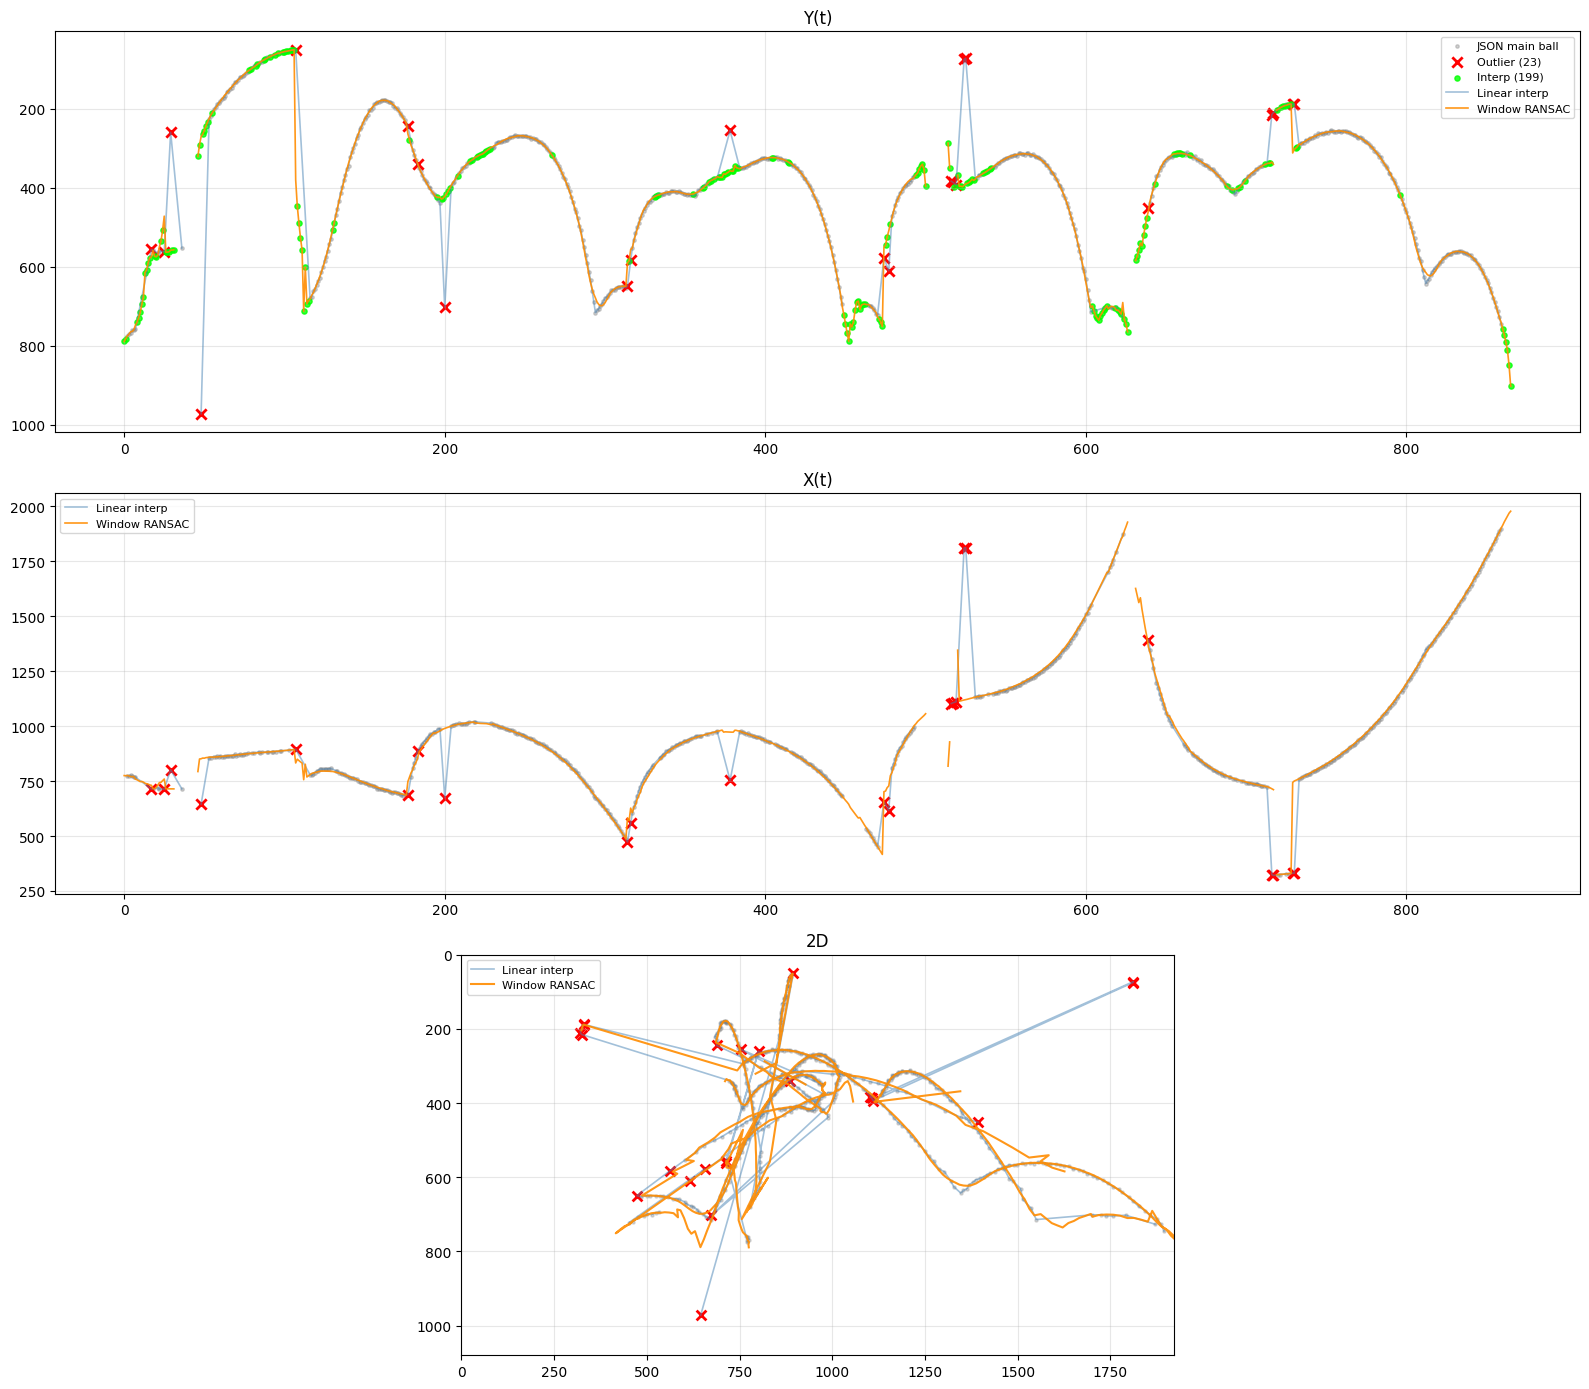

In [42]:
# ===== matplotlib 对比 =====
%matplotlib inline

coords_for_linear = [(np.nan, np.nan) if p is None else (float(p[0]), float(p[1])) for p in raw_coords]
segs = split_track_improved(coords_for_linear, max_gap=10)
linear_coords = [(np.nan, np.nan)] * n
for ss, se in segs:
    sub = [list(p) if is_valid(p) else None for p in coords_for_linear[ss:se+1]]
    linear_coords[ss:se+1] = interpolation(sub)

def to_xy(arr):
    xs = np.full(n, np.nan); ys = np.full(n, np.nan)
    for i, p in enumerate(arr):
        if is_valid(p): xs[i], ys[i] = float(p[0]), float(p[1])
    return xs, ys

raw_x, raw_y = to_xy(raw_coords)
lin_x, lin_y = to_xy(linear_coords)
ran_x, ran_y = to_xy(cleaned_coords)
out_mask = np.array([s == 'outlier_corrected' for s in point_status])
int_mask = np.array([s == 'winransac_interp' for s in point_status])

fig, axes = plt.subplots(3, 1, figsize=(16, 14))
fs = np.arange(n)

ax = axes[0]
ax.scatter(fs, raw_y, s=6, c='gray', alpha=0.35, label='JSON main ball')
ax.scatter(fs[out_mask], raw_y[out_mask], s=55, marker='x', c='red', lw=2, label=f'Outlier ({out_mask.sum()})')
ax.scatter(fs[int_mask], ran_y[int_mask], s=14, c='lime', alpha=0.8, label=f'Interp ({int_mask.sum()})')
ax.plot(fs, lin_y, color='steelblue', alpha=0.5, lw=1.2, label='Linear interp')
ax.plot(fs, ran_y, color='darkorange', alpha=0.9, lw=1.2, label='Window RANSAC')
ax.set_title('Y(t)'); ax.invert_yaxis(); ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[1]
ax.scatter(fs, raw_x, s=6, c='gray', alpha=0.35)
ax.scatter(fs[out_mask], raw_x[out_mask], s=55, marker='x', c='red', lw=2)
ax.plot(fs, lin_x, color='steelblue', alpha=0.5, lw=1.2, label='Linear interp')
ax.plot(fs, ran_x, color='darkorange', alpha=0.9, lw=1.2, label='Window RANSAC')
ax.set_title('X(t)'); ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[2]
ax.scatter(raw_x, raw_y, s=5, c='gray', alpha=0.3)
ax.scatter(raw_x[out_mask], raw_y[out_mask], s=50, marker='x', c='red', lw=2)
ax.plot(lin_x, lin_y, color='steelblue', alpha=0.5, lw=1.2, label='Linear interp')
ax.plot(ran_x, ran_y, color='darkorange', alpha=0.9, lw=1.5, label='Window RANSAC')
ax.set_xlim(0, fw); ax.set_ylim(fh, 0); ax.set_aspect('equal', adjustable='box')
ax.set_title('2D'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

/var/folders/fc/r8s93nts3nlfx246y_34jv440000gn/T/ipykernel_13746/1842183261.py:24: UserWarning: Glyph 27531 (\N{CJK UNIFIED IDEOGRAPH-6B8B}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/fc/r8s93nts3nlfx246y_34jv440000gn/T/ipykernel_13746/1842183261.py:24: UserWarning: Glyph 24046 (\N{CJK UNIFIED IDEOGRAPH-5DEE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/fc/r8s93nts3nlfx246y_34jv440000gn/T/ipykernel_13746/1842183261.py:24: UserWarning: Glyph 33258 (\N{CJK UNIFIED IDEOGRAPH-81EA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/fc/r8s93nts3nlfx246y_34jv440000gn/T/ipykernel_13746/1842183261.py:24: UserWarning: Glyph 36866 (\N{CJK UNIFIED IDEOGRAPH-9002}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/fc/r8s93nts3nlfx246y_34jv440000gn/T/ipykernel_13746/1842183261.py:24: UserWarning: Glyph 24212 (\N{CJK UNIFIED IDEOGRAPH-5E94}) missing from font(s) DejaVu

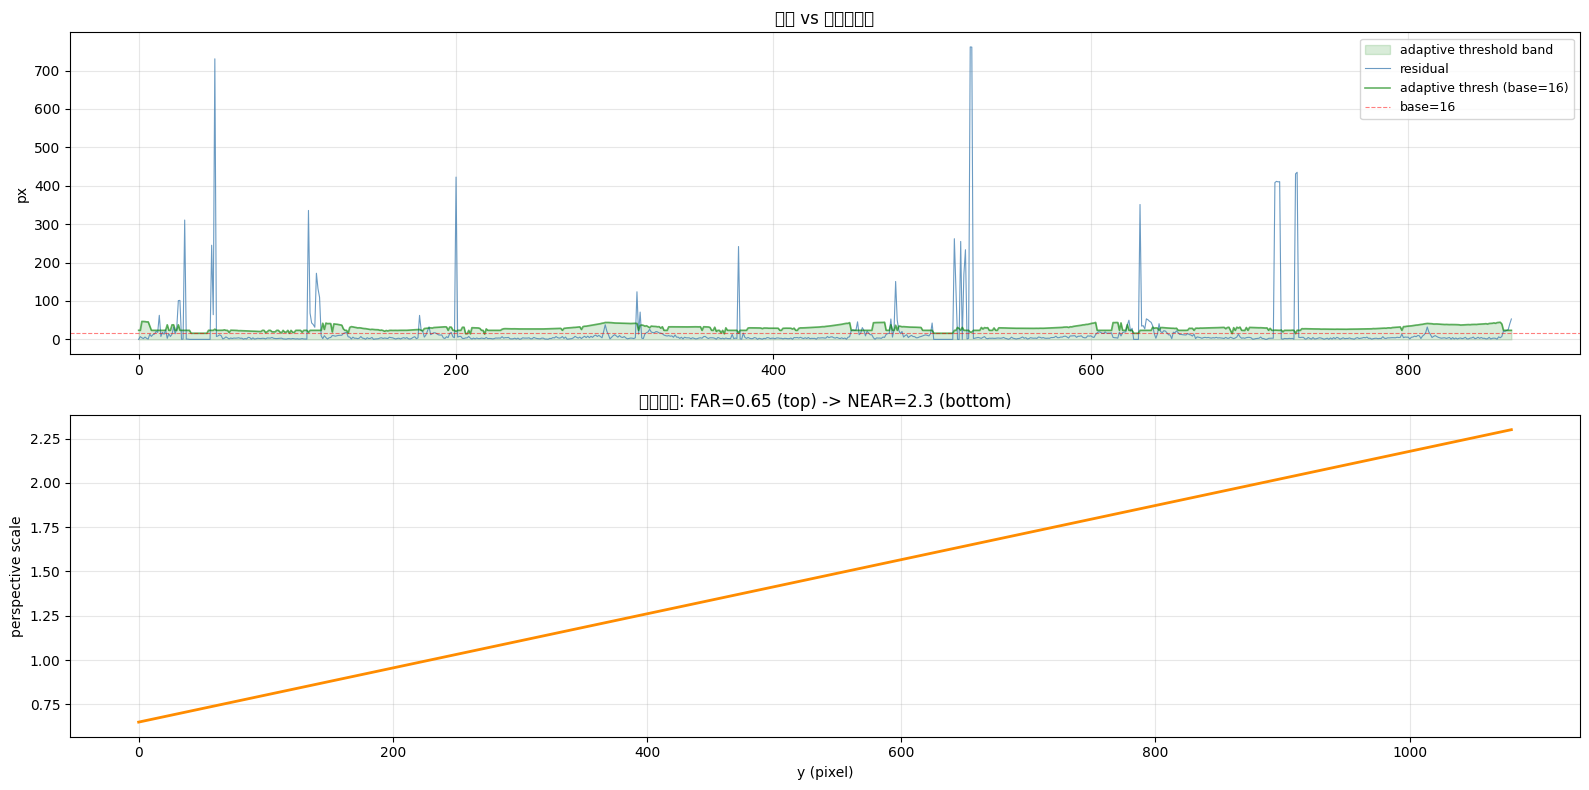

In [43]:
# ===== 残差 vs 自适应阈值 =====
th_arr = np.array(adaptive_thresh_per_frame)
res_list = []
for i in range(n):
    if fit_info[i] is not None:
        res_list.append(fit_info[i][2] if not np.isnan(fit_info[i][2]) else 0)
    else:
        res_list.append(0)

fig, axes = plt.subplots(2, 1, figsize=(16, 8))
ax = axes[0]
ax.fill_between(range(n), 0, th_arr, alpha=0.15, color='green', label='adaptive threshold band')
ax.plot(res_list, color='steelblue', alpha=0.8, lw=0.8, label='residual')
ax.plot(th_arr, color='green', alpha=0.6, lw=1.2, label=f'adaptive thresh (base={BASE_INLIER_THRESH})')
ax.axhline(BASE_INLIER_THRESH, color='red', ls='--', lw=0.8, alpha=0.5, label=f'base={BASE_INLIER_THRESH}')
ax.set_title('残差 vs 自适应阈值'); ax.set_ylabel('px'); ax.legend(fontsize=9); ax.grid(alpha=0.3)

ax = axes[1]
yvs = np.linspace(0, fh, 200)
ax.plot(yvs, [perspective_threshold_scale(y, fh) for y in yvs], color='darkorange', lw=2)
ax.set_xlabel('y (pixel)'); ax.set_ylabel('perspective scale')
ax.set_title(f'透视缩放: FAR={FAR_THRESH_SCALE} (top) -> NEAR={NEAR_THRESH_SCALE} (bottom)')
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

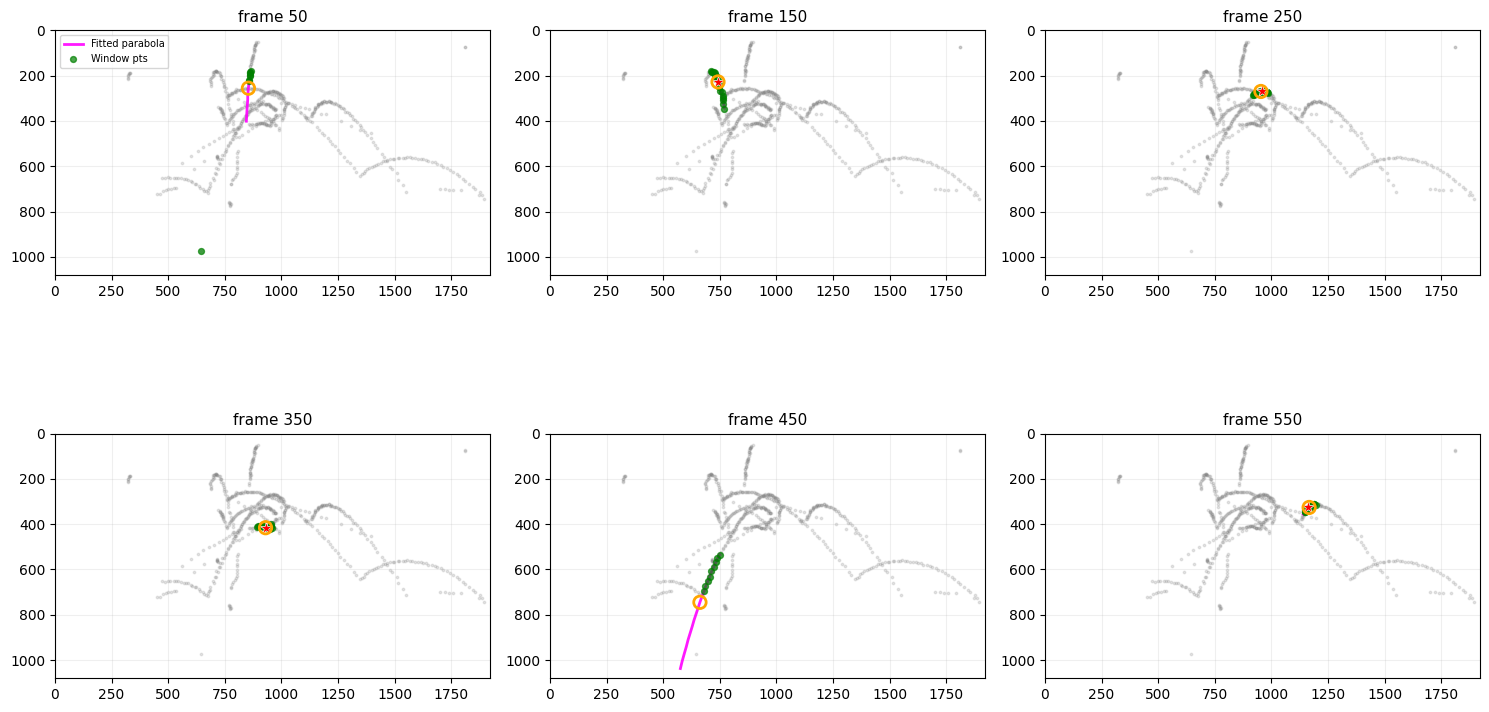

In [44]:
# ===== matplotlib: 选几个帧展示拟合曲线 + 上下文点 =====
sample_frames = [50, 150, 250, 350, 450, 550]
sample_frames = [f for f in sample_frames if f < n and fit_info[f] is not None]

ncols = 3
nrows = max(1, (len(sample_frames) + ncols - 1) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*5, nrows*4.5))
if nrows == 1: axes = [axes]

for ai, fi in enumerate(sample_frames):
    row, col = ai // ncols, ai % ncols
    ax = axes[row][col] if nrows > 1 else axes[col]

    # 原始散点
    ax.scatter(raw_x, raw_y, s=3, c='gray', alpha=0.2)

    # 当前帧
    if is_valid(raw_coords[fi]):
        ax.scatter(raw_x[fi], raw_y[fi], s=80, marker='*', c='red', edgecolors='white', lw=0.5, zorder=5)
    ax.scatter(ran_x[fi], ran_y[fi], s=80, marker='o', facecolors='none', edgecolors='orange', lw=2, zorder=5)

    # 拟合曲线
    _, _, _, _, curve_pts, ctx_pts = fit_info[fi]
    if curve_pts:
        cx_arr = [p[0] for p in curve_pts]
        cy_arr = [p[1] for p in curve_pts]
        ax.plot(cx_arr, cy_arr, color='magenta', alpha=0.9, lw=2, label='Fitted parabola')
    if ctx_pts:
        gx = [p[0] for p in ctx_pts]
        gy = [p[1] for p in ctx_pts]
        ax.scatter(gx, gy, s=18, c='green', alpha=0.7, zorder=3, label='Window pts')

    ax.set_xlim(0, fw); ax.set_ylim(fh, 0)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(f'frame {fi}', fontsize=11)
    ax.grid(alpha=0.2)
    if ai == 0: ax.legend(fontsize=7)

# 隐藏空子图
for ai in range(len(sample_frames), nrows * ncols):
    row, col = ai // ncols, ai % ncols
    ax = axes[row][col] if nrows > 1 else axes[col]
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [45]:
# ===== 视频渲染：RANSAC 轨迹 + 窗口拟合曲线 =====
os.makedirs(os.path.dirname(OUTPUT_VIDEO), exist_ok=True)
TAIL_LEN = 30

cap = cv2.VideoCapture(INPUT_VIDEO)
writer = cv2.VideoWriter(OUTPUT_VIDEO, cv2.VideoWriter_fourcc(*'mp4v'), fps, (fw, fh))

pbar = tqdm(total=ntotal, desc='渲染')
for i in range(ntotal):
    ret, frame = cap.read()
    if not ret: break
    canvas = frame.copy()

    # 0) 窗口拟合曲线 + 上下文点（优先级最高，画在最底层）
    if SHOW_PRED_CURVE and fit_info[i] is not None:
        _, _, _, _, curve_pts, ctx_pts = fit_info[i]
        # 曲线：洋红
        if curve_pts:
            for k in range(1, len(curve_pts)):
                cv2.line(canvas, curve_pts[k-1], curve_pts[k], (255, 0, 255), 2, cv2.LINE_AA)
        # 上下文点：绿
        if ctx_pts:
            for cx, cy in ctx_pts:
                cv2.circle(canvas, (cx, cy), 3, (0, 220, 0), -1, cv2.LINE_AA)
                cv2.circle(canvas, (cx, cy), 4, (0, 100, 0), 1, cv2.LINE_AA)
        # 预测点 vs raw 点的连线
        if is_valid(raw_coords[i]) and is_valid(cleaned_coords[i]):
            px, py = int(cleaned_coords[i][0]), int(cleaned_coords[i][1])
            rx, ry = int(raw_coords[i][0]), int(raw_coords[i][1])
            link = (0, 140, 255) if point_status[i] == 'outlier_corrected' else (160, 160, 160)
            cv2.line(canvas, (px, py), (rx, ry), link, 1, cv2.LINE_AA)

    # 1) 轨迹拖尾 (橙色渐变)
    for k in range(max(0, i - TAIL_LEN), i):
        if is_valid(cleaned_coords[k]) and is_valid(cleaned_coords[k+1]):
            x1, y1 = int(cleaned_coords[k][0]), int(cleaned_coords[k][1])
            x2, y2 = int(cleaned_coords[k+1][0]), int(cleaned_coords[k+1][1])
            alpha = (k - max(0, i - TAIL_LEN) + 1) / TAIL_LEN
            cv2.line(canvas, (x1, y1), (x2, y2), (0, int(200*alpha), int(255*alpha)), 2, cv2.LINE_AA)

    # 2) 清理后点
    if is_valid(cleaned_coords[i]):
        cx, cy = int(cleaned_coords[i][0]), int(cleaned_coords[i][1])
        if point_status[i] == 'inlier':
            cv2.circle(canvas, (cx, cy), 7, (0, 200, 255), -1)
        elif point_status[i] == 'outlier_corrected':
            cv2.drawMarker(canvas, (cx, cy), (0, 100, 255), cv2.MARKER_DIAMOND, 12, 2)
        elif point_status[i] == 'winransac_interp':
            cv2.circle(canvas, (cx, cy), 6, (0, 200, 255), 1)

    # 3) JSON 主球轨迹
    if raw_coords[i] is not None:
        rx, ry = int(raw_coords[i][0]), int(raw_coords[i][1])
        if point_status[i] == 'outlier_corrected':
            cv2.drawMarker(canvas, (rx, ry), (100, 100, 100), cv2.MARKER_TILTED_CROSS, 14, 1)
        else:
            cv2.circle(canvas, (rx, ry), 3, (150, 150, 150), -1)

    # 4) HUD
    st = point_status[i]
    cm = {'inlier': (0,200,255), 'outlier_corrected': (0,100,255),
          'winransac_interp': (0,200,255), 'raw_kept': (200,200,200), 'gap': (100,100,100)}
    c = cm.get(st, (255,255,255))
    lines = [f"frame {i}/{ntotal}", f"status: {st}"]
    if fit_info[i] is not None:
        _, nin, res, is_out, _, _ = fit_info[i]
        th = adaptive_thresh_per_frame[i]
        lines.append(f"inliers={nin}  res={res:.1f}/{th:.1f}px")
        lines.append(f"curve: {len(fit_info[i][4])}pts  ctx: {len(fit_info[i][5])}pts")
    for li, txt in enumerate(lines):
        yy = 35 + li * 28
        cv2.putText(canvas, txt, (20, yy), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,0,0), 4, cv2.LINE_AA)
        cv2.putText(canvas, txt, (20, yy), cv2.FONT_HERSHEY_SIMPLEX, 0.6, c, 2, cv2.LINE_AA)

    # 5) 图例
    legend = [
        ('RANSAC inlier',    (0,200,255)),
        ('outlier corrected', (0,100,255)),
        ('RANSAC interp',    (0,200,255)),
        ('Prediction curve', (255,0,255)),
        ('Window ctx pts',   (0,220,0)),
        ('JSON main ball',   (150,150,150)),
    ]
    lx, ly = fw - 270, fh - 30 - len(legend) * 24
    for li, (name, col) in enumerate(legend):
        yy = ly + li * 24
        cv2.rectangle(canvas, (lx, yy-12), (lx+260, yy+6), (0,0,0), -1)
        cv2.circle(canvas, (lx+12, yy-4), 4, col, -1)
        cv2.putText(canvas, name, (lx+22, yy+1), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255,255,255), 1)

    writer.write(canvas)
    pbar.update(1)

cap.release(); writer.release(); pbar.close()
print(f'视频已保存: {OUTPUT_VIDEO}')

渲染: 100%|██████████| 866/866 [00:06<00:00, 143.24it/s]

视频已保存: /Users/mac/PycharmProjects/tennis_data_master/cv/data/output/winransac_preview.mp4


In [46]:
# ===== 视频渲染：仅球坐标（干净版）=====
BALL_ONLY_OUTPUT = str(PROJECT_ROOT / "cv/data/output/winransac_ball_only.mp4")
TAIL_LEN = 40
BALL_RADIUS = 6
TAIL_THICKNESS = 2

cap = cv2.VideoCapture(INPUT_VIDEO)
writer = cv2.VideoWriter(BALL_ONLY_OUTPUT, cv2.VideoWriter_fourcc(*'mp4v'), fps, (fw, fh))

pbar = tqdm(total=ntotal, desc='渲染球轨迹')
for i in range(ntotal):
    ret, frame = cap.read()
    if not ret: break
    canvas = frame.copy()

    # 拖尾
    for k in range(max(0, i - TAIL_LEN), i):
        if is_valid(cleaned_coords[k]) and is_valid(cleaned_coords[k+1]):
            x1, y1 = int(cleaned_coords[k][0]), int(cleaned_coords[k][1])
            x2, y2 = int(cleaned_coords[k+1][0]), int(cleaned_coords[k+1][1])
            alpha = (k - max(0, i - TAIL_LEN) + 1) / TAIL_LEN
            cv2.line(canvas, (x1, y1), (x2, y2),
                     (0, int(200 * alpha), int(255 * alpha)), TAIL_THICKNESS, cv2.LINE_AA)

    # 当前球点
    if is_valid(cleaned_coords[i]):
        cx, cy = int(cleaned_coords[i][0]), int(cleaned_coords[i][1])
        cv2.circle(canvas, (cx, cy), BALL_RADIUS, (0, 200, 255), -1, cv2.LINE_AA)
        cv2.circle(canvas, (cx, cy), BALL_RADIUS, (0, 120, 200), 1, cv2.LINE_AA)

    writer.write(canvas)
    pbar.update(1)

cap.release(); writer.release(); pbar.close()
print(f'视频已保存: {BALL_ONLY_OUTPUT}')

渲染球轨迹: 100%|██████████| 866/866 [00:04<00:00, 173.94it/s]

视频已保存: /Users/mac/PycharmProjects/tennis_data_master/cv/data/output/winransac_ball_only.mp4
